<h1 align='center' style='color:purple'>Clustering With K Means - Python Tutorial</h1>

## 3. The K-Means algorithm and its objective function

### 3.1 Steps

1. **Choose K** – the number of clusters.
2. **Initialise** K centroids $\mu_1, \dots, \mu_K$ (randomly picked points, or the smarter *k-means++* in scikit-learn).
3. **Assignment step** – give each point $x_i$ to the closest centroid using **Euclidean distance**:
$$d(x, \mu) = \sqrt{(x_1-\mu_1)^2 + (x_2-\mu_2)^2 + \dots}$$
$$c_i = \arg\min_{k}\; d(x_i, \mu_k)$$
4. **Update step** – move every centroid to the **mean** of the points assigned to it:
$$\mu_k = \frac{1}{|C_k|}\sum_{x_i \in C_k} x_i$$
5. **Repeat** steps 3–4 until the assignments (or centroids) stop changing — this is **convergence**.

### 3.2 What K-Means is minimising

K-Means minimises the **Within-Cluster Sum of Squares (WCSS)**, which scikit-learn calls **`inertia_`**:

$$\text{WCSS} = \sum_{k=1}^{K}\;\sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$$

* Each assignment step and each update step can only **decrease (or keep)** the WCSS ⇒ the algorithm is guaranteed to converge.
* But it converges to a **local** minimum, which depends on the starting centroids. That is why scikit-learn runs it several times (`n_init`) and keeps the best result.

## 4. Numerical worked example (by hand) ✍️

Let's cluster **7 points** into **K = 2** clusters completely by hand, and then let Python confirm every number.

| Point | x | y |
|---|---|---|
| A | 1.0 | 1.0 |
| B | 1.5 | 2.0 |
| C | 3.0 | 4.0 |
| D | 5.0 | 7.0 |
| E | 3.5 | 5.0 |
| F | 4.5 | 5.0 |
| G | 3.5 | 4.5 |

**Initial centroids** (chosen as two far-apart points): $\mu_1 = A = (1, 1)$ and $\mu_2 = D = (5, 7)$.

---

### 🔁 Iteration 1

**Assignment step.** Example calculation for point **B (1.5, 2)**:

$$d(B,\mu_1) = \sqrt{(1.5-1)^2 + (2-1)^2} = \sqrt{0.25+1} = \sqrt{1.25} = 1.118$$
$$d(B,\mu_2) = \sqrt{(1.5-5)^2 + (2-7)^2} = \sqrt{12.25+25} = \sqrt{37.25} = 6.103$$

$1.118 < 6.103$ ⇒ **B → Cluster 1**. Doing this for every point:

| Point | d to μ₁ (1, 1) | d to μ₂ (5, 7) | Assigned to |
|---|---|---|---|
| A | 0.000 | 7.211 | **C1** |
| B | 1.118 | 6.103 | **C1** |
| C | 3.606 | 3.606 | **C1** *(tie → first centroid)* |
| D | 7.211 | 0.000 | **C2** |
| E | 4.717 | 2.500 | **C2** |
| F | 5.315 | 2.062 | **C2** |
| G | 4.301 | 2.915 | **C2** |

> ⚠️ Point **C** is *exactly* the same distance from both centroids. By convention (and in NumPy's `argmin`) ties go to the **first** centroid.

**Update step.**

$$\mu_1 = \text{mean}(A,B,C) = \left(\tfrac{1+1.5+3}{3},\; \tfrac{1+2+4}{3}\right) = (1.833,\; 2.333)$$
$$\mu_2 = \text{mean}(D,E,F,G) = \left(\tfrac{5+3.5+4.5+3.5}{4},\; \tfrac{7+5+5+4.5}{4}\right) = (4.125,\; 5.375)$$

---

### 🔁 Iteration 2

| Point | d to μ₁ (1.833, 2.333) | d to μ₂ (4.125, 5.375) | Assigned to |
|---|---|---|---|
| A | 1.572 | 5.376 | C1 |
| B | 0.471 | 4.276 | C1 |
| C | 2.034 | **1.777** | **C2** ⬅ *changed!* |
| D | 5.640 | 1.846 | C2 |
| E | 3.145 | 0.729 | C2 |
| F | 3.771 | 0.530 | C2 |
| G | 2.734 | 1.075 | C2 |

Point **C** has moved to Cluster 2. **Update step:**

$$\mu_1 = \text{mean}(A,B) = (1.25,\; 1.5)$$
$$\mu_2 = \text{mean}(C,D,E,F,G) = \left(\tfrac{3+5+3.5+4.5+3.5}{5},\; \tfrac{4+7+5+5+4.5}{5}\right) = (3.9,\; 5.1)$$

---

### 🔁 Iteration 3

| Point | d to μ₁ (1.25, 1.5) | d to μ₂ (3.9, 5.1) | Assigned to |
|---|---|---|---|
| A | 0.559 | 5.022 | C1 |
| B | 0.559 | 3.920 | C1 |
| C | 3.052 | 1.421 | C2 |
| D | 6.657 | 2.195 | C2 |
| E | 4.161 | 0.412 | C2 |
| F | 4.776 | 0.608 | C2 |
| G | 3.750 | 0.721 | C2 |

No point changed cluster ⇒ the centroids stay at $(1.25, 1.5)$ and $(3.9, 5.1)$ ⇒ **converged ✅**

**Final clusters:** C1 = {A, B}, C2 = {C, D, E, F, G}

### 📉 WCSS at the end

$$\text{WCSS} = \underbrace{(0.25^2+0.5^2) + (0.25^2+0.5^2)}_{\text{C1: } A, B = 0.625} + \underbrace{(0.9^2+1.1^2) + (1.1^2+1.9^2) + (0.4^2+0.1^2) + (0.6^2+0.1^2) + (0.4^2+0.6^2)}_{\text{C2} = 7.9} = 8.525$$

WCSS went **33.25 → 11.23 → 8.525** across the iterations (computed with the centroids used in each assignment step) — it never increases.

Now let's check all of this with code 👇

## 5. Evaluation metrics for clustering 📏

Because clustering has **no ground-truth labels**, we can't use accuracy. Instead we use:

* **Internal metrics** – judge the clusters using only the data (compactness & separation).
* **External metrics** – compare to true labels, *only if* they happen to be available (e.g. for teaching datasets like Iris).

### 5.1 Internal metrics

| Metric | Formula / idea | Range | Better when | In sklearn |
|---|---|---|---|---|
| **WCSS / Inertia** | $\sum_k \sum_{x \in C_k}\lVert x-\mu_k\rVert^2$ — compactness | $[0, \infty)$ | **Lower** (but *always* falls as K grows) | `km.inertia_` |
| **Silhouette score** | $s(i) = \dfrac{b(i) - a(i)}{\max\{a(i), b(i)\}}$ averaged over all points | $[-1, 1]$ | **Higher** (≈1 great, ≈0 overlapping, <0 wrong cluster) | `silhouette_score` |


In the silhouette:
* $a(i)$ = average distance from point $i$ to the **other points in its own cluster** (how tight its cluster is),
* $b(i)$ = average distance from point $i$ to the points of the **nearest other cluster** (how far the neighbours are).

### 5.2 External metrics (need true labels)

| Metric | Range | Meaning |
|---|---|---|
| **Adjusted Rand Index (ARI)** | $[-1, 1]$ | 1 = perfect match with true labels, ≈0 = random labelling |
| **Normalized Mutual Information (NMI)** | $[0, 1]$ | 1 = clusters carry exactly the same information as the labels |

Both ignore the *names* of the clusters — cluster "0" vs "1" swapped still scores 1.0.

---

### ✍️ Hand calculation: silhouette of point A in the worked example

Final clusters: C1 = {A, B}, C2 = {C, D, E, F, G}.

**a(A)** – A's own cluster contains only B:
$$a(A) = d(A,B) = 1.118$$

**b(A)** – average distance from A to every point of C2:
$$b(A) = \frac{d(A,C)+d(A,D)+d(A,E)+d(A,F)+d(A,G)}{5} = \frac{3.606+7.211+4.717+5.315+4.301}{5} = \frac{25.150}{5} = 5.030$$

$$s(A) = \frac{5.030 - 1.118}{\max(1.118,\; 5.030)} = \frac{3.912}{5.030} = \mathbf{0.778}$$

A is **well inside** its cluster (close to 1). Let's verify, and compute all metrics for the worked example:

In [5]:
from sklearn.cluster import KMeans
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from matplotlib import pyplot as plt
from sklearn.metrics import silhouette_score
import numpy as np
%matplotlib inline

# Load the data set

In [6]:
df=pd.read_csv("income.csv")
df.head()

,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000


# Plot the scater plot

Text(0, 0.5, 'Income($)')

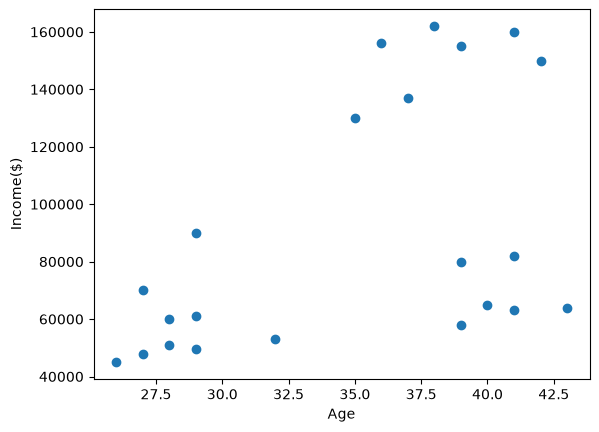

In [7]:
plt.scatter(df.Age,df['Income($)'])
plt.xlabel('Age')
plt.ylabel('Income($)')


By eye there are clearly **3 groups**: young/low income (bottom-left), older/high income (top-right) and older/medium income (bottom-right).

# Bulid and Train the model

In [8]:
km = KMeans (n_clusters=3)
y_predicted = km.fit_predict(df[['Age','Income($)']])
y_predicted 

D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


array([0, 0, 2, 2, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 0, 0, 2],
      dtype=int32)

# Assgin the cluster table to the samples 

In [9]:
df['cluster'] = y_predicted
df.head()

,Name,Age,Income($),cluster
0,Rob,27,70000,0
1,Michael,29,90000,0
2,Mohan,29,61000,2
3,Ismail,28,60000,2
4,Kory,42,150000,1


In [10]:
km.cluster_centers_

array([[3.40000000e+01, 8.05000000e+04],
       [3.82857143e+01, 1.50000000e+05],
       [3.29090909e+01, 5.61363636e+04]])

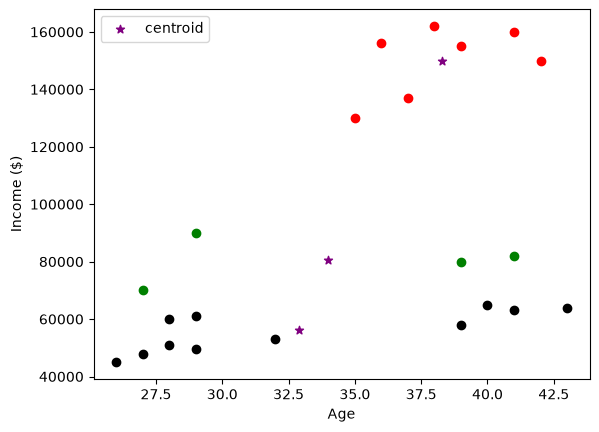

In [11]:
df1 = df[df.cluster==0]
df2 = df[df.cluster==1]
df3 = df[df.cluster==2]
plt.scatter(df1.Age,df1['Income($)'],color='green')
plt.scatter(df2.Age,df2['Income($)'],color='red')
plt.scatter(df3.Age,df3['Income($)'],color='black')
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='purple',marker='*',label='centroid')
plt.xlabel('Age')
plt.ylabel('Income ($)')
plt.legend()

The clusters are cut **horizontally by income only** — some young people end up with older people. Why?

<h4 style='color:purple'>Preprocessing using min max scaler</h4>


**Min–Max scaling** squeezes every feature into the range $[0, 1]$:

$$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

**Worked example** for Rob (Age 27, Income 70,000). Age range is 26 → 43, Income range is 45,000 → 162,000:

In [12]:
scaler = MinMaxScaler()

df[['Income($)', 'Age']] = scaler.fit_transform(
    df[['Income($)', 'Age']]
)

In [13]:
df.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,0
1,Michael,0.176471,0.384615,0
2,Mohan,0.176471,0.136752,2
3,Ismail,0.117647,0.128205,2
4,Kory,0.941176,0.897436,1


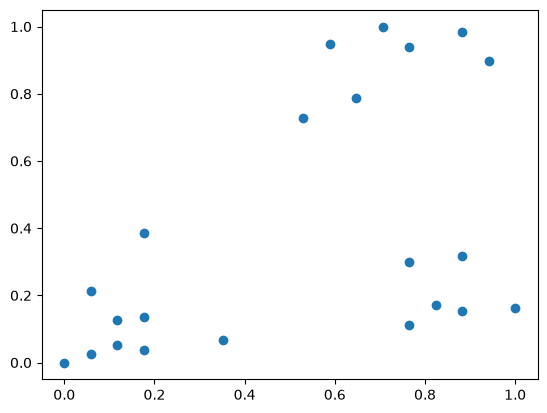

In [14]:
plt.scatter(df.Age,df['Income($)'])

In [15]:
km = KMeans(n_clusters=3)
y_predicted = km.fit_predict(df[['Age','Income($)']])
y_predicted

D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


array([1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2],
      dtype=int32)

In [16]:
df['cluster']=y_predicted
df.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,1
1,Michael,0.176471,0.384615,1
2,Mohan,0.176471,0.136752,1
3,Ismail,0.117647,0.128205,1
4,Kory,0.941176,0.897436,0


In [17]:
km.cluster_centers_

array([[0.72268908, 0.8974359 ],
       [0.1372549 , 0.11633428],
       [0.85294118, 0.2022792 ]])

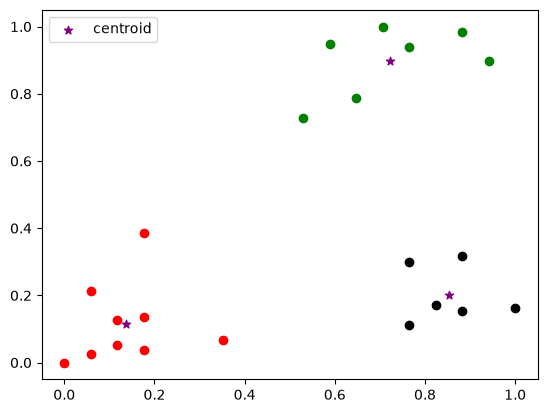

In [18]:
df1 = df[df.cluster==0]
df2 = df[df.cluster==1]
df3 = df[df.cluster==2]
plt.scatter(df1.Age,df1['Income($)'],color='green')
plt.scatter(df2.Age,df2['Income($)'],color='red')
plt.scatter(df3.Age,df3['Income($)'],color='black')
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='purple',marker='*',label='centroid')
plt.legend()

<h4 style='color:purple'>Elbow Plot</h4>

[![Picture1.png](https://i.postimg.cc/k5xhZXvY/Picture1.png)](https://postimg.cc/3yxB0h62)

# SSE and silhouette scores



---



In [19]:
X = df[['Age','Income($)']]
k_range = range(2,10)

sse, silhouette_scores = [], []

for k in k_range:
    km = KMeans(n_clusters=k, random_state= 42, n_init=10).fit(X)
    sse.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X, km.labels_))

D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than availabl

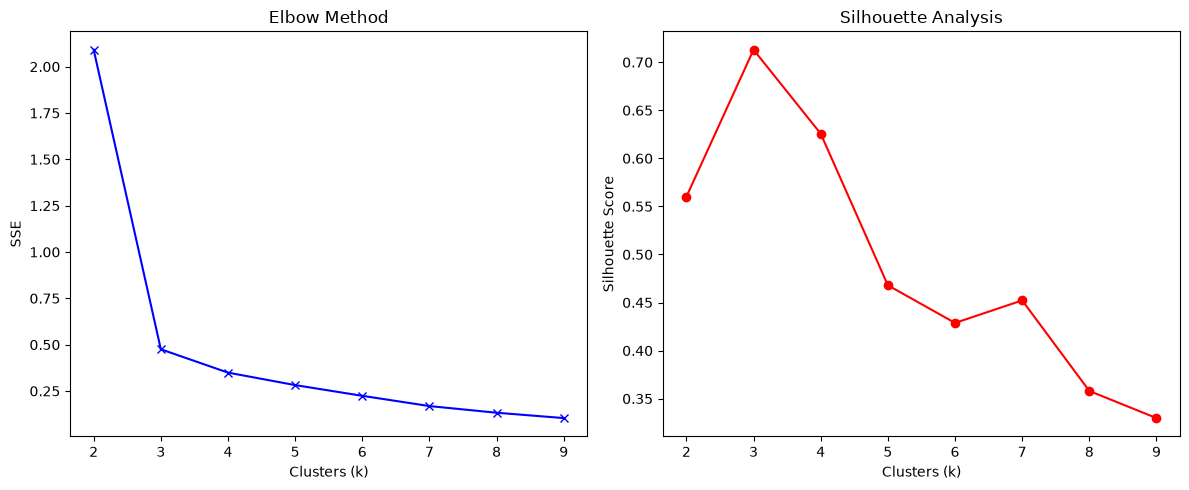

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].plot(k_range, sse, 'bx-')
ax[0].set(title='Elbow Method', xlabel='Clusters (k)', ylabel='SSE')

ax[1].plot(k_range, silhouette_scores, 'ro-')
ax[1].set(title='Silhouette Analysis', xlabel='Clusters (k)', ylabel='Silhouette Score')

plt.tight_layout()
plt.show()

# load the dataset

In [21]:
df = pd.read_csv("income.csv")

print(df.head())

X = df[['Age', 'Income($)']].to_numpy(dtype=float)

      Name  Age  Income($)
0      Rob   27      70000
1  Michael   29      90000
2    Mohan   29      61000
3   Ismail   28      60000
4     Kory   42     150000


# Z-score normalization

In [22]:
# Z-score normalization
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)

print("Standardized Data:\n", X_scaled[:5])

Standardized Data:
 [[-1.35605536 -0.48068427]
 [-1.00915747 -0.01015907]
 [-1.00915747 -0.69242061]
 [-1.18260641 -0.71594687]
 [ 1.24567876  1.40141653]]


# Define the custom K-Means algorithm

In [23]:
def kmeans(X, k, max_iters=100):
    np.random.seed(42)
    centroids = X[np.random.choice(len(X), k, replace=False)].copy()

    for _ in range(max_iters):
        labels = np.argmin(np.array([np.sum((X-c)**2, axis=1) for c in centroids]).T, axis=1)
        new_centroids = np.array([X[labels==i].mean(axis=0) if np.any(labels==i) else centroids[i] for i in range (k)])
        if np.allclose(centroids, new_centroids): break
        centroids = new_centroids

    labels = np.argmin(np.array([np.sum((X-c)**2, axis=1) for c in centroids]).T, axis=1)
    return centroids, labels

In [24]:
k = 3
centroids, labels = kmeans(X_scaled, k)

df['Cluster'] = labels

print(df.head())
print("Centroids:\n", centroids)

      Name  Age  Income($)  Cluster
0      Rob   27      70000        0
1  Michael   29      90000        0
2    Mohan   29      61000        0
3   Ismail   28      60000        0
4     Kory   42     150000        2
Centroids:
 [[-1.1247901  -0.74862223]
 [ 0.98550535 -0.51205261]
 [ 0.60143983  1.40141653]]


<h4 style='color:purple'>Exercise</h4>

## 📝 Lab Assignment: K-Means Clustering on the Wine Dataset — From Scratch vs. scikit-learn

### 🎯 Objective
Apply K-Means clustering to the **Wine dataset** in two ways:
1. a **from-scratch implementation**, written by you using only NumPy;
2. the **predefined `KMeans`** class from scikit-learn.

Evaluate both with standard clustering metrics and compare the results.

---

### 📂 Step 1 — Load the dataset
```python
from sklearn.datasets import load_wine
wine = load_wine()
X, y_true = wine.data, wine.target      # 178 wines, 13 chemical features, 3 cultivars
```
> ⚠️ **Do NOT use `y_true` for clustering.** Keep it aside and use it **only** for the external metrics (ARI, NMI) in Step 6.

---

### 🔍 Step 2 — Explore and preprocess
- Put `X` into a DataFrame with `wine.feature_names`. Show its shape, `head()` and `describe()`.
- Look at the feature ranges: for example, *proline* goes up to ~1680, while *hue* is around 1.
- Apply `StandardScaler`. **Explain in a markdown cell why scaling is necessary** for K-Means here.
- Use **PCA** to get 2 components (`PCA(n_components=2)`), **for plotting only**. Cluster on all 13 scaled features.

---

### 🛠️ Step 3 — K-Means from scratch
Write a function `kmeans_scratch(X, k, max_iters=100, n_init=10, seed=42)` using **only NumPy**. It must:
1. **Initialise** K centroids by picking random data points.
2. **Assign** each point to its nearest centroid using Euclidean distance.
3. **Update** each centroid to the mean of the points assigned to it.
4. **Stop** when the centroids no longer move (or `max_iters` is reached).
5. Repeat the whole run `n_init` times and keep the run with the **lowest WCSS**.
6. **Return** `centroids`, `labels`, `wcss` and the number of iterations.

Also write your own function to compute **WCSS**:
$$\text{WCSS} = \sum_{k=1}^{K}\sum_{x_i \in C_k}\lVert x_i-\mu_k\rVert^2$$

⭐ **Bonus:** implement the **silhouette score from scratch** and check that it matches `sklearn.metrics.silhouette_score`.

---

### 📦 Step 4 — K-Means with scikit-learn
```python
from sklearn.cluster import KMeans
km = KMeans(n_clusters=k, n_init=10, random_state=42)
labels_sk = km.fit_predict(X_scaled)
```
Report `km.cluster_centers_`, `km.inertia_` and `km.n_iter_`.

---

### 📈 Step 5 — Choose the optimal K
For **K = 2 to 10**, using **both** implementations:
- Plot the **Elbow curve** (WCSS vs K).
- Plot the **Silhouette score vs K**.
- State your chosen K and explain why. Does it match the 3 true cultivars?

---

### 📏 Step 6 — Evaluate both models
Fill in this table for your chosen K:

| Metric | Type | Better | Scratch | scikit-learn |
|---|---|---|---|---|
| WCSS / Inertia | Internal | ↓ Lower | | |
| Silhouette score | Internal | ↑ Higher (max 1) | | |

In [35]:
#Step 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

# Load Wine dataset
wine = load_wine()
X, y_true = wine.data, wine.target

print("Dataset Shape:", X.shape)

# Create DataFrame
df = pd.DataFrame(X, columns=wine.feature_names)

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Description:")
print(df.describe())


Dataset Shape: (178, 13)

First 5 Rows:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_dilu

Minimum Values:
alcohol                          11.03
malic_acid                        0.74
ash                               1.36
alcalinity_of_ash                10.60
magnesium                        70.00
total_phenols                     0.98
flavanoids                        0.34
nonflavanoid_phenols              0.13
proanthocyanins                   0.41
color_intensity                   1.28
hue                               0.48
od280/od315_of_diluted_wines      1.27
proline                         278.00
dtype: float64

Maximum Values:
alcohol                           14.83
malic_acid                         5.80
ash                                3.23
alcalinity_of_ash                 30.00
magnesium                        162.00
total_phenols                      3.88
flavanoids                         5.08
nonflavanoid_phenols               0.66
proanthocyanins                    3.58
color_intensity                   13.00
hue                                1.71
od280

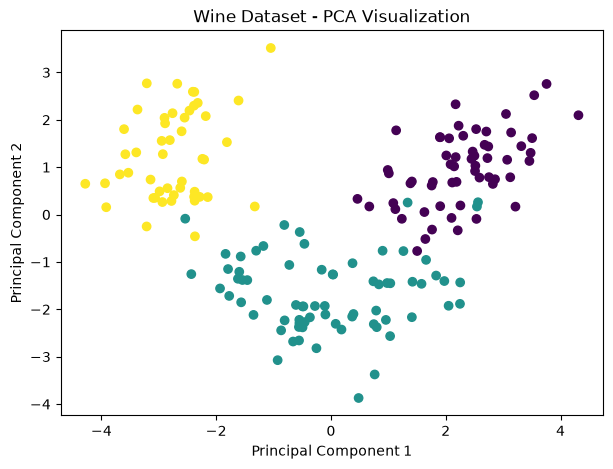

In [36]:
#Step 2
# Display feature ranges
print("Minimum Values:")
print(df.min())

print("\nMaximum Values:")
print(df.max())

# Standardize the dataset
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nStandardized Data (First 5 Rows):")
print(X_scaled[:5])

# Apply PCA for 2D visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("\nPCA Shape:", X_pca.shape)

# Plot original data using PCA
plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_true)
plt.title("Wine Dataset - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()


In [37]:
#Step 3:
# Function to calculate WCSS
def calculate_wcss(X, centroids, labels, k):
    wcss = 0

    for i in range(k):
        points = X[labels == i]

        if len(points) > 0:
            wcss += np.sum((points - centroids[i]) ** 2)

    return wcss


# K-Means implementation from scratch
def kmeans_scratch(X, k, max_iters=100, n_init=10, seed=42):

    best_wcss = float('inf')
    best_centroids = None
    best_labels = None
    best_iterations = 0

    for run in range(n_init):

        np.random.seed(seed + run)

        # Initialize random centroids
        centroids = X[
            np.random.choice(len(X), k, replace=False)
        ].copy()

        for iteration in range(max_iters):

            # Calculate Euclidean distances
            distances = np.linalg.norm(
                X[:, np.newaxis] - centroids,
                axis=2
            )

            # Assign points to nearest centroid
            labels = np.argmin(distances, axis=1)

            # Update centroids
            new_centroids = np.array([
                X[labels == i].mean(axis=0)
                if np.any(labels == i)
                else centroids[i]
                for i in range(k)
            ])

            # Check convergence
            if np.allclose(centroids, new_centroids):
                centroids = new_centroids
                break

            centroids = new_centroids

        # Final cluster assignment
        distances = np.linalg.norm(
            X[:, np.newaxis] - centroids,
            axis=2
        )

        labels = np.argmin(distances, axis=1)

        # Calculate WCSS
        wcss = calculate_wcss(X, centroids, labels, k)

        # Store best result
        if wcss < best_wcss:
            best_wcss = wcss
            best_centroids = centroids.copy()
            best_labels = labels.copy()
            best_iterations = iteration + 1

    return best_centroids, best_labels, best_wcss, best_iterations


# Run custom K-Means with K = 3
k = 3

centroids, labels, wcss, iterations = kmeans_scratch(
    X_scaled, k
)

print("Centroids:\n", centroids)
print("\nCluster Labels:\n", labels)
print("\nWCSS:", wcss)
print("Iterations:", iterations)


Centroids:
 [[-0.92607185 -0.39404154 -0.49451676  0.17060184 -0.49171185 -0.07598265
   0.02081257 -0.03353357  0.0582655  -0.90191402  0.46180361  0.27076419
  -0.75384618]
 [ 0.83523208 -0.30380968  0.36470604 -0.61019129  0.5775868   0.88523736
   0.97781956 -0.56208965  0.58028658  0.17106348  0.47398365  0.77924711
   1.12518529]
 [ 0.16490746  0.87154706  0.18689833  0.52436746 -0.07547277 -0.97933029
  -1.21524764  0.72606354 -0.77970639  0.94153874 -1.16478865 -1.29241163
  -0.40708796]]

Cluster Labels:
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 2 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 2 0 0 1 0 0 0 0 0 0 0 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]

WCSS: 1277.9284888446423
Iterations: 10


In [38]:
#Step 4:
# Create K-Means model
km = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=42
)

# Train the model
labels_sk = km.fit_predict(X_scaled)

print("Cluster Centers:\n", km.cluster_centers_)

print("\nCluster Labels:\n", labels_sk)

print("\nWCSS (Inertia):", km.inertia_)

print("Number of Iterations:", km.n_iter_)


Cluster Centers:
 [[-0.92607185 -0.39404154 -0.49451676  0.17060184 -0.49171185 -0.07598265
   0.02081257 -0.03353357  0.0582655  -0.90191402  0.46180361  0.27076419
  -0.75384618]
 [ 0.16490746  0.87154706  0.18689833  0.52436746 -0.07547277 -0.97933029
  -1.21524764  0.72606354 -0.77970639  0.94153874 -1.16478865 -1.29241163
  -0.40708796]
 [ 0.83523208 -0.30380968  0.36470604 -0.61019129  0.5775868   0.88523736
   0.97781956 -0.56208965  0.58028658  0.17106348  0.47398365  0.77924711
   1.12518529]]

Cluster Labels:
 [2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 0 0 2 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

WCSS (Inertia): 1277.928488844642
Number of Iterations: 7


D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than availabl

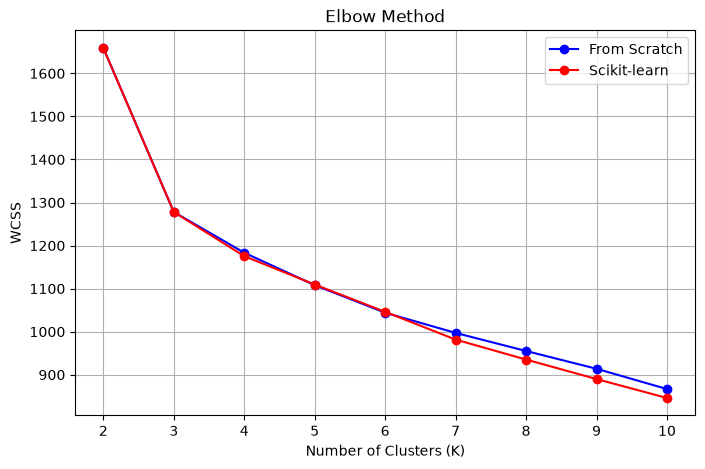

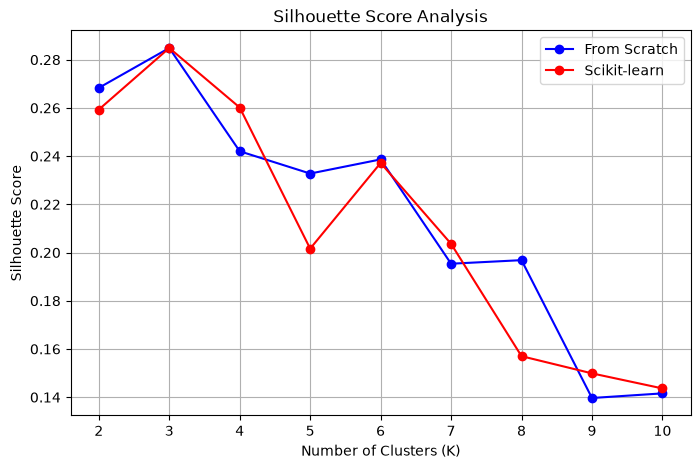

Best K From Scratch: 3
Best K Using Scikit-learn: 3


In [40]:
#Step 5
k_range = range(2, 11)

# Store evaluation results
sse_scratch = []
sse_sklearn = []

sil_scratch = []
sil_sklearn = []

for k in k_range:

    # K-Means from scratch
    centroids, labels, wcss, iterations = kmeans_scratch(
        X_scaled, k
    )

    sse_scratch.append(wcss)
    sil_scratch.append(silhouette_score(X_scaled, labels))

    # K-Means using scikit-learn
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels_sk_k = model.fit_predict(X_scaled)

    sse_sklearn.append(model.inertia_)
    sil_sklearn.append(
        silhouette_score(X_scaled, labels_sk_k)
    )


# Plot Elbow Method
plt.figure(figsize=(8, 5))

plt.plot(k_range, sse_scratch, 'bo-', label='From Scratch')
plt.plot(k_range, sse_sklearn, 'ro-', label='Scikit-learn')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.legend()
plt.grid()
plt.show()


# Plot Silhouette Scores
plt.figure(figsize=(8, 5))

plt.plot(k_range, sil_scratch, 'bo-', label='From Scratch')
plt.plot(k_range, sil_sklearn, 'ro-', label='Scikit-learn')

plt.title("Silhouette Score Analysis")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.legend()
plt.grid()
plt.show()


# Display best K values
print("Best K From Scratch:", list(k_range)[np.argmax(sil_scratch)])
print("Best K Using Scikit-learn:", list(k_range)[np.argmax(sil_sklearn)])


D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


FINAL MODEL COMPARISON
                             Metric     Type  From Scratch  Scikit-learn
                     WCSS / Inertia Internal   1277.928489   1277.928489
                   Silhouette Score Internal      0.284859      0.284859
          Adjusted Rand Index (ARI) External      0.897495      0.897495
Normalized Mutual Information (NMI) External      0.875894      0.875894


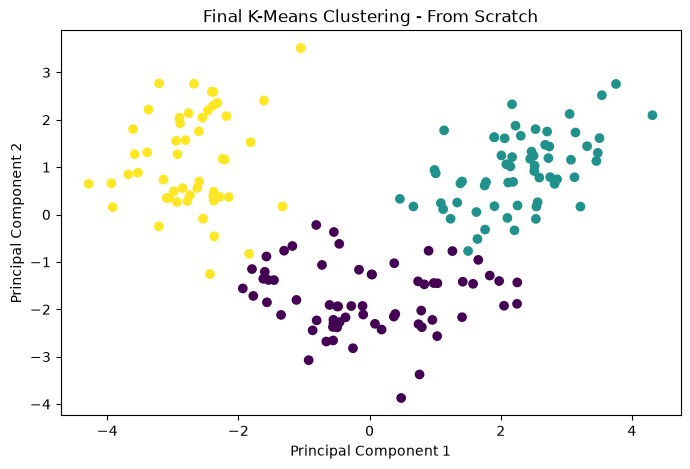

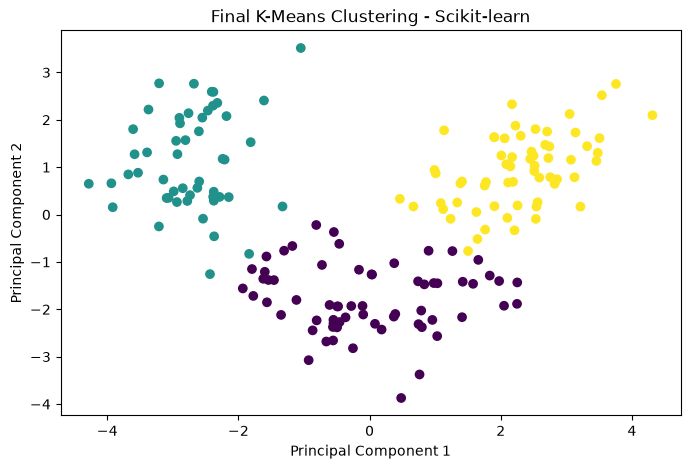

In [44]:
#Step 6
# Run both models using chosen K = 3
k = 3

# Scratch implementation
centroids, labels, wcss_scratch, iterations = kmeans_scratch(
    X_scaled, k
)

# Scikit-learn implementation
km = KMeans(
    n_clusters=k,
    n_init=10,
    random_state=42
)

labels_sk = km.fit_predict(X_scaled)


# Calculate evaluation metrics
scratch_silhouette = silhouette_score(X_scaled, labels)
sklearn_silhouette = silhouette_score(X_scaled, labels_sk)

scratch_ari = adjusted_rand_score(y_true, labels)
sklearn_ari = adjusted_rand_score(y_true, labels_sk)

scratch_nmi = normalized_mutual_info_score(y_true, labels)
sklearn_nmi = normalized_mutual_info_score(y_true, labels_sk)


# Create comparison table
comparison = pd.DataFrame({
    'Metric': [
        'WCSS / Inertia',
        'Silhouette Score',
        'Adjusted Rand Index (ARI)',
        'Normalized Mutual Information (NMI)'
    ],

    'Type': [
        'Internal',
        'Internal',
        'External',
        'External'
    ],

    'From Scratch': [
        wcss_scratch,
        scratch_silhouette,
        scratch_ari,
        scratch_nmi
    ],

    'Scikit-learn': [
        km.inertia_,
        sklearn_silhouette,
        sklearn_ari,
        sklearn_nmi
    ]
})

print("FINAL MODEL COMPARISON")
print(comparison.to_string(index=False))


# Visualize final clusters using PCA
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels,
    cmap='viridis'
)

plt.title("Final K-Means Clustering - From Scratch")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()


plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels_sk,
    cmap='viridis'
)

plt.title("Final K-Means Clustering - Scikit-learn")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()
